In [68]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [72]:
device = 'cuda:0'
# model = create_agent(cf, device)
# memories = create_memories(model.actor, cf.num_envs, device=device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# model.train()
# 1
model = UOROModel(1, 30, 1, 1e-3, device)

using GRU


In [73]:
model.initialize_state(device)

In [74]:
x=torch.randn(1, 1, 1, device=device)
y=torch.ones(1, 1, device=device)
model.forward(x, y)

/isaac-sim/memoryPerceiver/memory_perceiver/core/uoro.py:101: UserWarning: Using a target size (torch.Size([1, 1])) that is different to the input size (torch.Size([1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  loss = torch.nn.functional.mse_loss(y_1[0], y)


(0.8331941962242126,
 None,
 tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
           0., 0., 0., 0., 0., 0., 0.]]], device='cuda:0', requires_grad=True),
 tensor([[[-0.0207, -0.0090, -0.0359,  0.0855,  0.0106,  0.0309,  0.0500,
           -0.0364, -0.1074, -0.0550,  0.0666, -0.0592, -0.0299, -0.0042,
           -0.0671, -0.0020,  0.0270, -0.0438, -0.0539,  0.0716,  0.0147,
            0.0336,  0.0676,  0.0876, -0.0203,  0.0552, -0.0357,  0.0342,
            0.0162,  0.0621]]], device='cuda:0', grad_fn=<CudnnRnnBackward0>))

In [75]:
loss_all=[]

In [76]:
l = []
loss_acc=0
for n in range(10000):
    x=(2*np.pi*n/10)*torch.ones(1, 1, 1, device=device)
    y=((2*np.pi*n/10)*torch.ones(1, 1, device=device)).sin()
    loss, _, _, _ = model.forward(x, y)
    loss_all.append(loss)
    loss_acc += loss
    if n%1000 == 0:
        print(loss_acc)
        loss_acc=0

0.008486146107316017


544.5909700747579
543.1317777968943
543.1324601657689
543.1324591822922
543.1319066025317


KeyboardInterrupt: 

In [38]:
l = []
loss_acc=0
for n in range(20000):
    for i in range(4):
        l.append(torch.randn(1, 1, 2, device=device))
    if len(l) > 1:
        x = l[-1]
        x_lagged = l.pop(0)
        y = x_lagged.mean(-1).detach()
        loss, _, _, _ = model.forward(x, y)
        loss_all.append(loss)
        loss_acc += loss
        if n%1000 == 0:
            print(loss_acc)
            loss_acc=0

0.0002618695725686848


KeyboardInterrupt: 

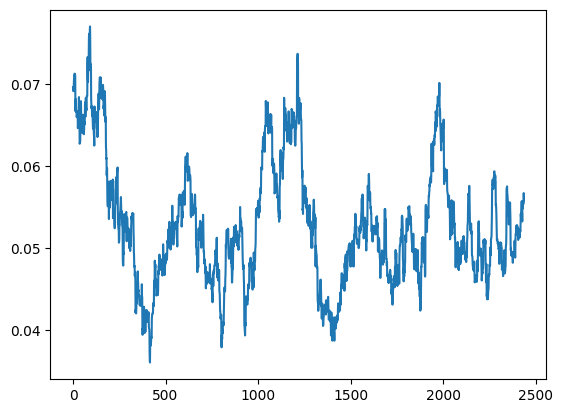

In [46]:
# plt.plot(loss_all)
h=100
plt.plot([sum(loss_all[i: i+h])/h for i in range(int(len(loss_all)/h))])
plt.show()

In [88]:
torch.tensor(loss_all)[:5000].mean()

tensor(4.0921)